# Trabajo Integrador 2: RAG con documentos de Sanidad

**Material adaptado para evaluar los CCT 108/75, CCT 103/75 y CCT 122/75**

---

## Objetivo
Construir y poner a prueba un RAG local sobre 3 Convenios Colectivos de Trabajo de Sanidad, dejando visibles la extracción, el corte, la búsqueda y la generación.

In [1]:
import os
from pathlib import Path

import gradio as gr
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

load_dotenv(".env")
print("Librerías cargadas.")

c:\Users\lea_1\Desktop\Trabajo Practico Integrador 2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Librerías cargadas.


C:\Users\lea_1\AppData\Local\Temp\ipykernel_15740\731775917.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


## 1. Declarar y cargar el corpus de 3 documentos reales
Cargamos los tres convenios colectivos exigidos para la entrega (`CCT 108/75`, `CCT 103/75` y `CCT 122/75`) guardados dentro de la carpeta `datos/`.

In [2]:
nombres_cct = [
    "CCT108-Texto Completo.pdf",
    "CCT103-Texto Completo.pdf",
    "CCT122-Texto Completo.pdf",
]
carpeta_datos = Path("datos")

if not all((carpeta_datos / nombre).is_file() for nombre in nombres_cct):
    faltantes = [
        nombre
        for nombre in nombres_cct
        if not (carpeta_datos / nombre).is_file()
    ]
    raise FileNotFoundError(
        "No encontré estos PDF en datos/: " + ", ".join(faltantes)
    )

rutas_cct = [carpeta_datos / nombre for nombre in nombres_cct]
MODELO_GENERADOR = os.getenv("OLLAMA_MODEL", "granite4:latest")
MODELO_EMBEDDINGS = os.getenv("OLLAMA_EMBEDDING_MODEL", "bge-m3")

paginas_corpus = []
for ruta in rutas_cct:
    cargador = PyPDFLoader(str(ruta))
    paginas = cargador.load()
    paginas_corpus.extend(paginas)
    print(f"Cargado: {ruta.name} ({len(paginas)} páginas)")

print(f"Total de páginas cargadas en el corpus: {len(paginas_corpus)}")

Cargado: CCT108-Texto Completo.pdf (12 páginas)
Cargado: CCT103-Texto Completo.pdf (10 páginas)
Cargado: CCT122-Texto Completo.pdf (14 páginas)
Total de páginas cargadas en el corpus: 36


## 2. Medir la extracción y comparar formas de cortar

Antes de indexar medimos cuántos caracteres se extrajeron de cada página y comparamos dos configuraciones. `chunk_size` y `chunk_overlap` se expresan en caracteres; no existe un tamaño universal. En estos convenios elegimos el corte amplio porque reduce el riesgo de separar el encabezado de un artículo de su inciso y porcentaje, pero dejamos visible la alternativa breve para evaluar ese supuesto.

La gráfica también permite detectar una falla de extracción: una página con muy pocos caracteres puede contener una tabla, una imagen, columnas o texto que el cargador no pudo leer. Eso es un problema del PDF o de la extracción, no de Chroma ni del modelo generador.

| Versión | `chunk_size` | `chunk_overlap` | Uso en este notebook |
|---|---:|---:|---|
| Breve | 500 | 80 | Comparación y diagnóstico |
| Amplia | 1.100 | 180 | Índice principal del RAG |

El solapamiento conserva parte del final de un fragmento al comienzo del siguiente. Cambiar un parámetro por vez permite atribuir mejor cualquier mejora o deterioro.

Fragmentos breves: 439
Fragmentos amplios: 196
Separadores normativos usados: ['\n \n', '\n\n']
Corte elegido para el índice: amplio (1100 caracteres, 180 de solapamiento)


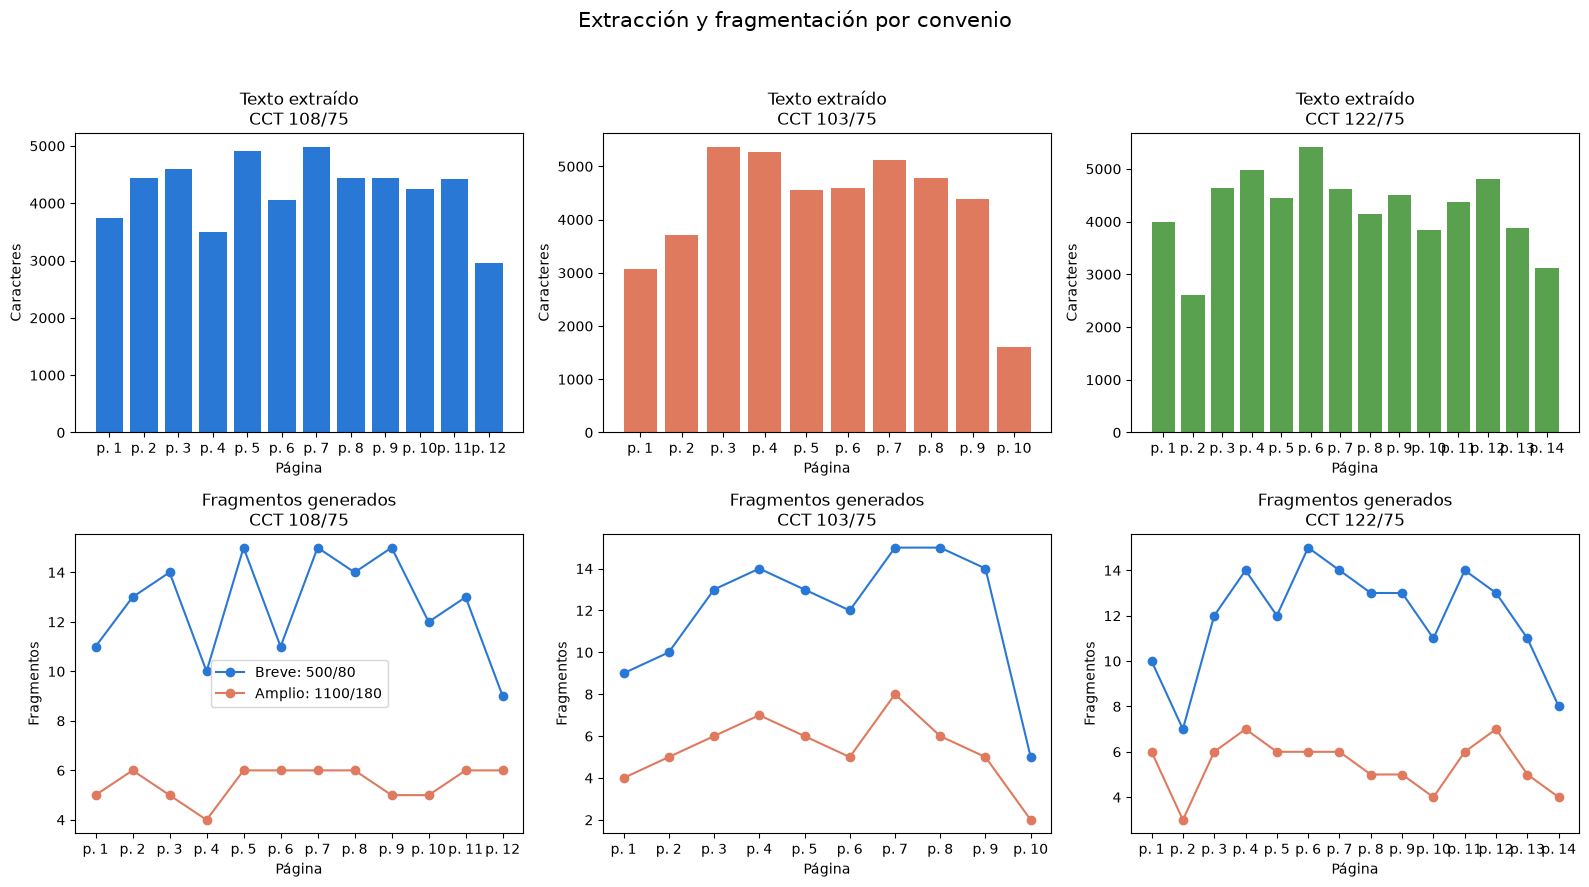


Detalle de páginas analizadas:
- CCT108-Texto Completo.pdf
Pág. 1: 3740 caracteres
- CCT108-Texto Completo.pdf
Pág. 2: 4442 caracteres
- CCT108-Texto Completo.pdf
Pág. 3: 4593 caracteres
- CCT108-Texto Completo.pdf
Pág. 4: 3490 caracteres
- CCT108-Texto Completo.pdf
Pág. 5: 4918 caracteres
- CCT108-Texto Completo.pdf
Pág. 6: 4052 caracteres
- CCT108-Texto Completo.pdf
Pág. 7: 4976 caracteres
- CCT108-Texto Completo.pdf
Pág. 8: 4437 caracteres
- CCT108-Texto Completo.pdf
Pág. 9: 4432 caracteres
- CCT108-Texto Completo.pdf
Pág. 10: 4242 caracteres
- CCT108-Texto Completo.pdf
Pág. 11: 4430 caracteres
- CCT108-Texto Completo.pdf
Pág. 12: 2959 caracteres
- CCT103-Texto Completo.pdf
Pág. 1: 3076 caracteres
- CCT103-Texto Completo.pdf
Pág. 2: 3715 caracteres
- CCT103-Texto Completo.pdf
Pág. 3: 5359 caracteres
- CCT103-Texto Completo.pdf
Pág. 4: 5277 caracteres
- CCT103-Texto Completo.pdf
Pág. 5: 4555 caracteres
- CCT103-Texto Completo.pdf
Pág. 6: 4591 caracteres
- CCT103-Texto Completo.pdf
P

In [3]:
TAMANO_BREVE = 500
SOLAPAMIENTO_BREVE = 80
TAMANO_AMPLIO = 1100
SOLAPAMIENTO_AMPLIO = 180
SEPARADORES_NORMATIVOS = ["\n \n", "\n\n", "\n", " ", ""]

divisor_breve = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_BREVE,
    chunk_overlap=SOLAPAMIENTO_BREVE,
    separators=SEPARADORES_NORMATIVOS,
)
divisor_amplio = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_AMPLIO,
    chunk_overlap=SOLAPAMIENTO_AMPLIO,
    separators=SEPARADORES_NORMATIVOS,
)

fragmentos_breves = divisor_breve.split_documents(paginas_corpus)
fragmentos_amplios = divisor_amplio.split_documents(paginas_corpus)
fragmentos = fragmentos_amplios

caracteres_por_pagina = {}
for pagina in paginas_corpus:
    fuente = Path(pagina.metadata["source"]).name
    clave = f"{fuente}\nPág. {pagina.metadata['page'] + 1}"
    caracteres_por_pagina[clave] = len(pagina.page_content)

conteo_breve = {}
conteo_amplio = {}
for grupo, conteo in [
    (fragmentos_breves, conteo_breve),
    (fragmentos_amplios, conteo_amplio),
]:
    for documento in grupo:
        fuente = Path(documento.metadata["source"]).name
        clave = f"{fuente}\nPág. {documento.metadata['page'] + 1}"
        conteo[clave] = conteo.get(clave, 0) + 1

print("Fragmentos breves:", len(fragmentos_breves))
print("Fragmentos amplios:", len(fragmentos_amplios))
print("Separadores normativos usados:", repr(SEPARADORES_NORMATIVOS[:2]))
print("Corte elegido para el índice: amplio (1100 caracteres, 180 de solapamiento)")

abreviaturas = {
    "CCT108-Texto Completo.pdf": "CCT 108/75",
    "CCT103-Texto Completo.pdf": "CCT 103/75",
    "CCT122-Texto Completo.pdf": "CCT 122/75",
}
colores = {"CCT 108/75": "#2a78d6", "CCT 103/75": "#e07a5f", "CCT 122/75": "#59a14f"}
orden_convenios = list(abreviaturas)

fig, ejes = plt.subplots(2, 3, figsize=(16, 9), squeeze=False)
for columna, nombre_archivo in enumerate(orden_convenios):
    convenio = abreviaturas[nombre_archivo]
    claves_convenio = [
        clave for clave in caracteres_por_pagina
        if clave.startswith(nombre_archivo + "\n")
    ]
    paginas = [clave.split("\n")[1].replace("Pág. ", "p. ") for clave in claves_convenio]
    color = colores[convenio]

    ejes[0, columna].bar(
        paginas,
        [caracteres_por_pagina[clave] for clave in claves_convenio],
        color=color,
    )
    ejes[0, columna].set_title(convenio)
    ejes[0, columna].set_xlabel("Página")
    ejes[0, columna].set_ylabel("Caracteres")
    ejes[0, columna].tick_params(axis="x", labelrotation=0)

    ejes[1, columna].plot(
        paginas,
        [conteo_breve.get(clave, 0) for clave in claves_convenio],
        marker="o",
        label="Breve: 500/80",
        color="#2a78d6",
    )
    ejes[1, columna].plot(
        paginas,
        [conteo_amplio.get(clave, 0) for clave in claves_convenio],
        marker="o",
        label="Amplio: 1100/180",
        color="#e07a5f",
    )
    ejes[1, columna].set_title(convenio)
    ejes[1, columna].set_xlabel("Página")
    ejes[1, columna].set_ylabel("Fragmentos")
    ejes[1, columna].tick_params(axis="x", labelrotation=0)

fig.suptitle("Extracción y fragmentación por convenio", fontsize=15)
ejes[0, 0].set_title("Texto extraído\nCCT 108/75")
ejes[0, 1].set_title("Texto extraído\nCCT 103/75")
ejes[0, 2].set_title("Texto extraído\nCCT 122/75")
ejes[1, 0].set_title("Fragmentos generados\nCCT 108/75")
ejes[1, 1].set_title("Fragmentos generados\nCCT 103/75")
ejes[1, 2].set_title("Fragmentos generados\nCCT 122/75")
ejes[1, 0].legend()
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

print("\nDetalle de páginas analizadas:")
for clave, caracteres in caracteres_por_pagina.items():
    print(f"- {clave}: {caracteres} caracteres")
print("\nMuestra del primer fragmento amplio:\n", fragmentos_amplios[0].page_content[:700])

## 3. Crear el índice vectorial persistente (ChromaDB)

Reconstruimos la colección cada vez que cambia el corpus o el corte. Así evitamos mezclar fragmentos viejos con los nuevos. La carpeta persistente conserva los vectores, pero la colección se elimina y se crea de nuevo de manera deliberada.

In [4]:
CARPETA_INDICE = "chroma_db_cct_sanidad"
NOMBRE_COLECCION = "cct_sanidad_3_docs_bge_m3_amplio"
embeddings = OllamaEmbeddings(model=MODELO_EMBEDDINGS)

indice_rag = Chroma(
    collection_name=NOMBRE_COLECCION,
    embedding_function=embeddings,
    persist_directory=CARPETA_INDICE,
)

if indice_rag.get(limit=1)["ids"]:
    indice_rag.delete_collection()
    indice_rag = Chroma(
        collection_name=NOMBRE_COLECCION,
        embedding_function=embeddings,
        persist_directory=CARPETA_INDICE,
    )

if not fragmentos:
    raise ValueError(
        "No hay fragmentos para indexar. Revisá la carga de los PDF y la extracción."
    )

identificadores = [f"frag_amplio_{i}" for i in range(len(fragmentos))]
indice_rag.add_documents(documents=fragmentos, ids=identificadores)
print("Fragmentos indexados en ChromaDB:", len(indice_rag.get()["ids"]))

Fragmentos indexados en ChromaDB: 196


## 4. Cadena RAG
Definición de prompt con restricción de evidencias y carga del modelo local.

In [5]:
plantilla = ChatPromptTemplate.from_messages([
    (
        "system",
        "Sos un asistente para consultar convenios colectivos de sanidad. "
        "Respondé en español y sólo con información explícita del contexto. "
        "Cada afirmación debe llevar la cita [1], [2] o [3] de la evidencia "
        "que la respalda. No combines porcentajes, días, artículos ni "
        "condiciones de documentos o convenios diferentes. Si la pregunta "
        "pide comparar convenios, escribí una afirmación separada para cada "
        "convenio y mantené cada dato asociado a su fuente. Si el contexto "
        "contiene la respuesta, no agregues una abstención. Si el contexto "
        "no contiene una respuesta suficiente, respondé exactamente: No "
        "encuentro esa información en los documentos. No completes con "
        "conocimiento general ni inventes citas.",
    ),
    (
        "human",
        "Contexto recuperado:\n{contexto}\n\nPregunta: {pregunta}",
    ),
])

modelo = ChatOllama(model=MODELO_GENERADOR, temperature=0)
cadena_rag = plantilla | modelo | StrOutputParser()

## 5. Laboratorio de fallas y pruebas (3 documentos reales)

Cada caso separa tres preguntas: ¿se extrajo el texto?, ¿se recuperó el fragmento correcto?, ¿el modelo interpretó sin mezclar fuentes? La consulta sobre Terapia Intensiva está formulada como una pregunta cotidiana y verificable. Conserva la palabra **mensual** porque el mismo CCT también menciona un adicional del 30% por cama excedente, que se calcula sobre la retribución diaria y responde a otra situación.

La distancia de Chroma sirve para ordenar candidatos, no es una probabilidad ni demuestra que una respuesta sea verdadera. Por eso se imprime siempre el texto y la procedencia.


Pregunta: ¿Cuántos días de licencia especial por matrimonio establece el CCT 108/75?
Respuesta: [1] En el CCT 108/75, establece que el personal tendrá derecho a las siguientes licencias continuadas y pagas, en iguales condiciones que la licencia anual, por matrimonio: 15 días. [1]
Evidencia recuperada:
  [1] CCT 108/75, página 8 | distancia 0.778
  [2] CCT 122/75, página 11 | distancia 0.820
  [3] CCT 122/75, página 10 | distancia 0.861

Pregunta: ¿Qué adicional mensual reciben las enfermeras y auxiliares que trabajan en Terapia Intensiva según el CCT 103/75?
Respuesta: Las enfermeras que trabajan en Terapia Intensiva percibirán un adicional mensual del 20% sobre su sueldo básico inicial de categoría. Para las auxiliares de enfermería, este adicional será del 10% sobre su sueldo básico inicial. [1]
Evidencia recuperada:
  [1] CCT 103/75, página 5 | distancia 0.666
  [2] CCT 122/75, página 7 | distancia 0.753
  [3] CCT 122/75, página 4 | distancia 0.763

Pregunta: ¿Cuántos días de lice

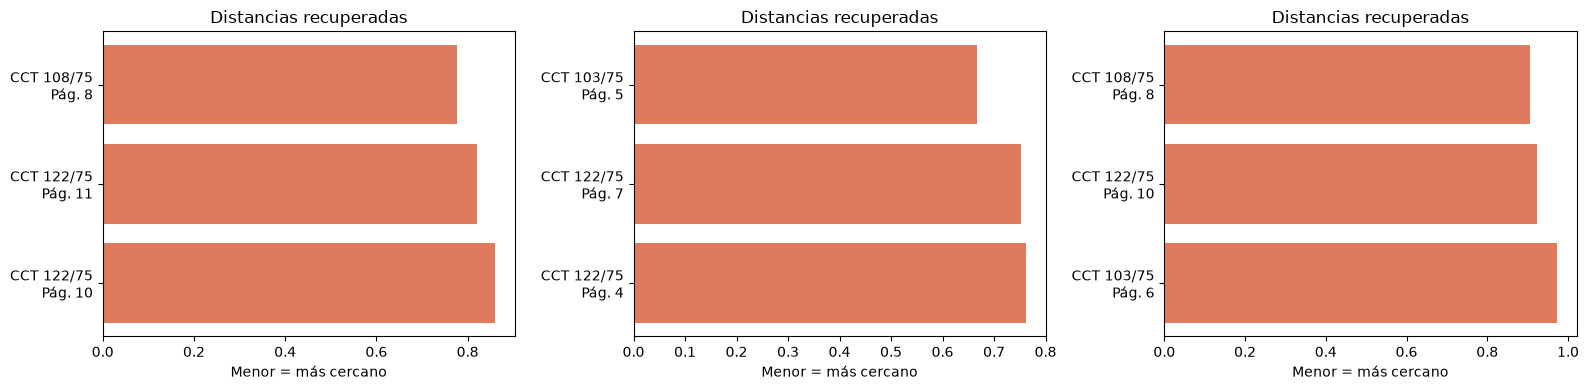

In [6]:
K = 3
casos_de_prueba = [
    "¿Cuántos días de licencia especial por matrimonio establece el CCT 108/75?",
    "¿Qué adicional mensual reciben las enfermeras y auxiliares que trabajan en Terapia Intensiva según el CCT 103/75?",
    "¿Cuántos días de licencia continuada y paga por matrimonio otorga el CCT 122/75 y cuántos el CCT 108/75?",
]

def recuperar_evidencia(pregunta: str, k: int = K):
    hallazgos = indice_rag.similarity_search_with_score(query=pregunta, k=k)
    contexto = ""
    referencias = []

    for numero, (documento, distancia) in enumerate(hallazgos, start=1):
        fuente = Path(documento.metadata.get("source", "Desconocida")).name
        convenio = abreviaturas.get(fuente, fuente)
        pagina = documento.metadata.get("page", 0) + 1
        referencia = f"{convenio}, página {pagina}"
        referencias.append((numero, referencia, distancia))
        contexto += f"[{numero}] {referencia}\n{documento.page_content}\n\n"

    return hallazgos, contexto, referencias

resultados_prueba = []
for caso in casos_de_prueba:
    hallazgos, contexto_del_caso, referencias = recuperar_evidencia(caso)
    respuesta = cadena_rag.invoke(
        {"contexto": contexto_del_caso, "pregunta": caso}
    )
    resultados_prueba.append(
        {"pregunta": caso, "respuesta": respuesta, "hallazgos": hallazgos}
    )

    print("\n" + "=" * 80)
    print("Pregunta:", caso)
    print("Respuesta:", respuesta)
    print("Evidencia recuperada:")
    for numero, referencia, distancia in referencias:
        print(f"  [{numero}] {referencia} | distancia {distancia:.3f}")

fig, ejes = plt.subplots(1, len(resultados_prueba), figsize=(16, 4), squeeze=False)
for eje, resultado in zip(ejes[0], resultados_prueba):
    etiquetas = []
    distancias = []
    for documento, distancia in resultado["hallazgos"]:
        fuente = Path(documento.metadata.get("source", "Desconocida")).name
        convenio = abreviaturas.get(fuente, fuente)
        pagina = documento.metadata.get("page", 0) + 1
        etiquetas.append(f"{convenio}\nPág. {pagina}")
        distancias.append(distancia)
    eje.barh(etiquetas[::-1], distancias[::-1], color="#e07a5f")
    eje.set_title("Distancias recuperadas")
    eje.set_xlabel("Menor = más cercano")
plt.tight_layout()
plt.show()

## 6. Tabla de pruebas (exigida en las pautas de entrega)

| Documento propio | Pregunta respondible | Página o sección esperada | ¿Qué recuperó? | ¿Qué interpretó el modelo? | Límite observado |
|---|---|---|---|---|---|
| **CCT 108/75** | ¿Cuántos días de licencia por matrimonio establece? | Art. 27 inc. a, pág. 8 | Fragmento del artículo 27 | 15 días continuados y pagos | Un corte pequeño puede separar el título de la licencia del número de días. |
| **CCT 103/75** | ¿Qué adicional mensual reciben las enfermeras y auxiliares que trabajan en Terapia Intensiva? | Adicional mensual por función, pág. 5 | Fragmento del adicional de Terapia Intensiva | 20% para enfermeras y 10% para auxiliares | La palabra “mensual” ayuda a no confundirlo con el 30% diario por cama excedente. |
| **CCT 122/75** | ¿Cuántos días de licencia por matrimonio establece? | Art. 22 inc. a, pág. 10 u 11 | Fragmento de licencias especiales | 14 días continuados y pagos | Al comparar convenios, cada cifra debe conservar su fuente. |

**Diagnóstico.** Si una página tiene poco texto, el problema está en la extracción. Si los fragmentos pertinentes no aparecen entre los primeros resultados, el problema está en el corte o la recuperación. Si la evidencia sí aparece pero la respuesta mezcla artículos o porcentajes, el problema está en la generación o en la redacción de la pregunta.

## 7. Interfaz Gradio local con trazabilidad de fuentes

La interfaz usa la misma función de recuperación que las pruebas. Muestra por separado la respuesta generada y los fragmentos que realmente recibió el modelo, incluyendo archivo, página y distancia. La evidencia visible permite auditar una respuesta y distinguir una cita correcta de una cita inventada.

In [7]:
def consultar(pregunta_usuario: str) -> tuple[str, str]:
    if not pregunta_usuario.strip():
        return "Escribí una pregunta.", "Todavía no se consultaron fuentes."

    hallazgos, contexto_usuario, referencias = recuperar_evidencia(pregunta_usuario)
    fuentes = ""

    for (numero, referencia, distancia), (documento, _) in zip(referencias, hallazgos):
        fuentes += f"**[{numero}] {referencia}** (distancia {distancia:.3f})\n\n"
        fuentes += f"```text\n{documento.page_content}\n```\n\n"

    respuesta_usuario = cadena_rag.invoke(
        {"contexto": contexto_usuario, "pregunta": pregunta_usuario}
    )
    return respuesta_usuario, fuentes

interfaz = gr.Interface(
    fn=consultar,
    inputs=gr.Textbox(
        label="Pregunta sobre CCT 108/75, CCT 103/75 y CCT 122/75",
        lines=3,
    ),
    outputs=[
        gr.Textbox(label="Respuesta del modelo"),
        gr.Markdown(label="Fragmentos recuperados y enviados al modelo"),
    ],
    title="RAG local: Convenios Colectivos de Sanidad",
    description=(
        "Consultá los convenios y verificá cada afirmación contra la evidencia "
        "recuperada, el archivo y la página original."
    ),
)

interfaz.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
